# Plotting functions

In [1]:
import numpy as np
from belfast.isochrone_utils import load_default_regularized_PARSECv2_Mini_interpolator, load_default_regularized_PARSECv2_u_interpolator
from belfast.plot_utils import plot_isomass_tracks, create_interp_func_PARS, plot_hrd_isochrones, plot_cmd_isochrones
import matplotlib.pyplot as plt


## Select and load an interpolation function
Please note that interpolation functions may not reproduce pre-MS and near-TAMS phases well.

In [2]:
# Standard regridding of isochrones
# Better covering early to middle evolutionary phases
# interp_func, *_ = load_default_regularized_PARSECv2_Mini_interpolator(grid_type="without_inc", label_list=[0, 1])

# Regridding via re-parameterization
# Better covering latter evolutionary phases
interp_func, *_ = load_default_regularized_PARSECv2_u_interpolator(grid_type="without_inc", label_list=[0, 1])

Loaded u-regularized grid.
grid_type: without_inc
label_list: [0, 1]
interp_variable_list: ['Mini', 'Age', 'MH', 'omega_ini']
interp_variable_list_regular: ['u', 'Age', 'MH', 'omega_ini']
interp_output_list: ['Mass', 'omega', 'logL', 'logTe', 'Req', 'Rpol']
u_grid shape: (1392,)
grid_outputs shape: (1392, 219, 13, 7, 6)
grid_bounds shape: (219, 13, 7, 2)
grid_outputs dtype: float32
grid_bounds dtype: float32
read_all_at_once: True
save_float32: True
u_save_range: [0.0, 1.0]
u_grid_was_cropped: False
n_u_original: 1392
n_u_saved: 1392
total grid memory: 635.11 MB (0.62 GB)


## Evolution of $T_{\rm eff}$, $L$, $R_{\rm eq}$, and $R_{\rm pol}$

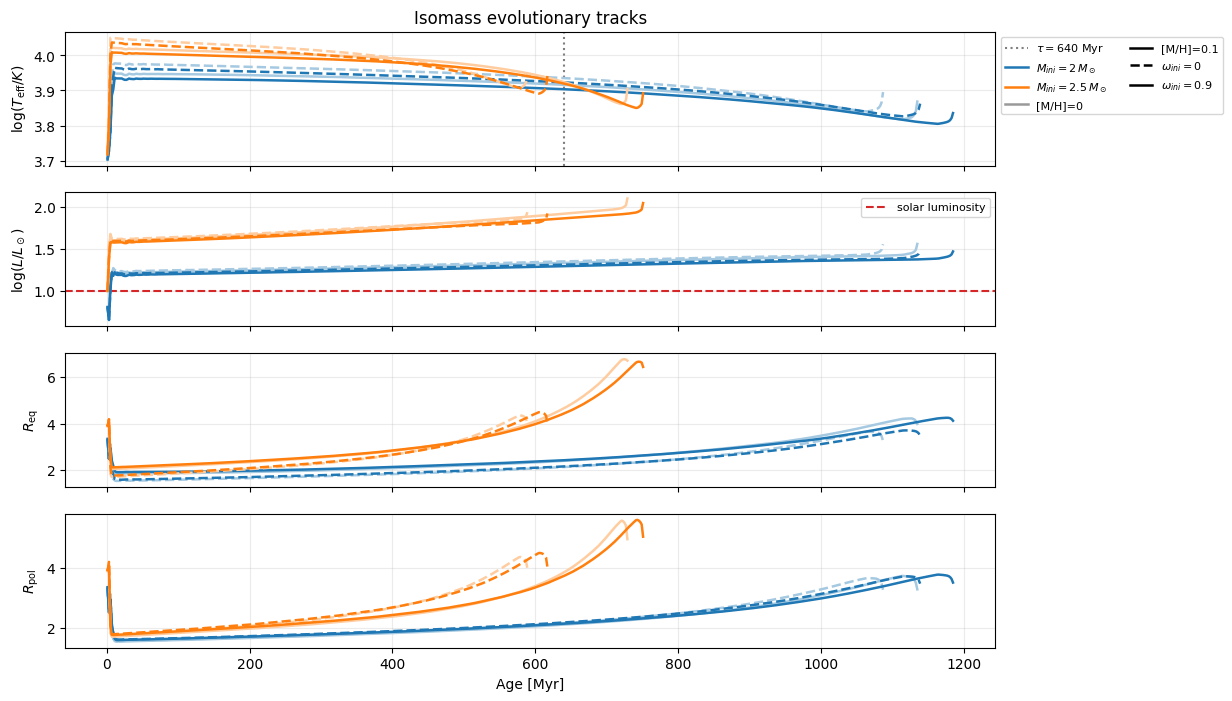

In [3]:
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)

axes[0].axvline(x=640, color='tab:grey', ls=':', lw=1.5, label=r'$\tau = 640$ Myr')
axes[1].axhline(y=1.0, color='tab:red', ls='--', lw=1.5, label='solar luminosity')

fig, axes = plot_isomass_tracks(
    interp_func,
    Mini=[2, 2.5],
    omega_ini=[0, 0.9],
    MH=[0, 0.1],
    axes=axes,
    legend=True,
    legend_loc='upper left',
    legend_bbox=(1, 1)
)

plt.show()

## HRD

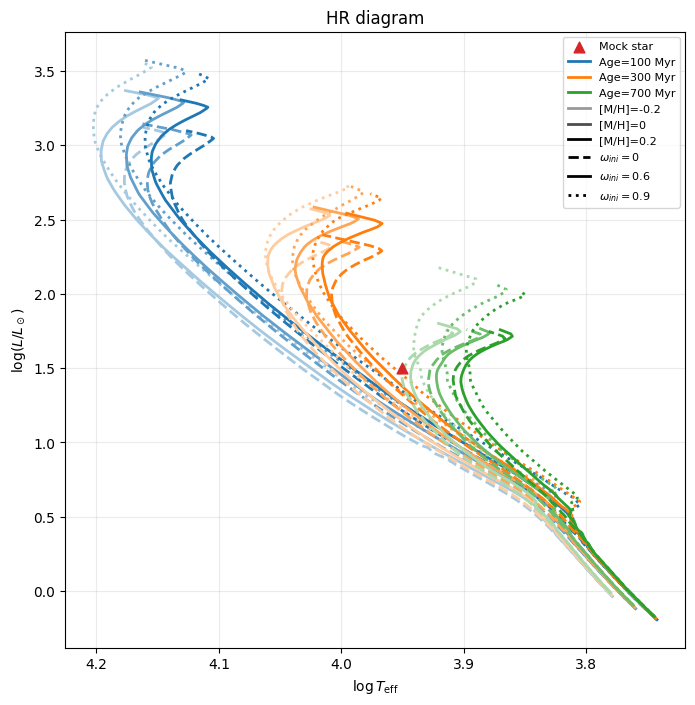

In [4]:
fig, ax = plt.subplots(figsize=[8, 8])

ax.scatter(3.95, 1.5, s=60,
           marker="^", color="tab:red", label="Mock star", zorder=100,)

plot_hrd_isochrones(
    interp_func,
    Age=[100, 300, 700],
    MH=[-0.2, 0.0, 0.2],
    omega_ini=[0.0, 0.6, 0.9],
    ax=ax,
    legend=True,
)

plt.show()

# CMD
When plotting CMDs, there are two ways:
* Using photometry from PARSEC isochrones (the DIRECT method; requires approximately 16 GB of memory).
* Using photometry calculated analytically by PARS (the PARS method; requires approximately 1 GB of memory).

### CMDs using photometry from PARSEC isochrones

In [ ]:
# Standard regridding of isochrones
# Better covering early to middle evolutionary phases
# interp_func_DIRECT, *_ = load_default_regularized_PARSECv2_Mini_interpolator(grid_type="with_inc", label_list=[0, 1])

# Regridding via re-parameterization
# Better covering latter evolutionary phases
# interp_func_DIRECT, *_ = load_default_regularized_PARSECv2_u_interpolator(grid_type="with_inc", label_list=[0, 1])

### CMDs using photometry from PARSEC isochrones

In [5]:
interp_func_PARS = create_interp_func_PARS(
    interp_func=interp_func,
    PARS_nz=100,
    PARS_MH_offset=-0.046,
    show_progress=True,
)

100%|██████████| 18/18 [01:41<00:00,  5.63s/it]


## Select a interp_func

In [6]:
# interp_func_cmd = interp_func_DIRECT
interp_func_cmd = interp_func_PARS

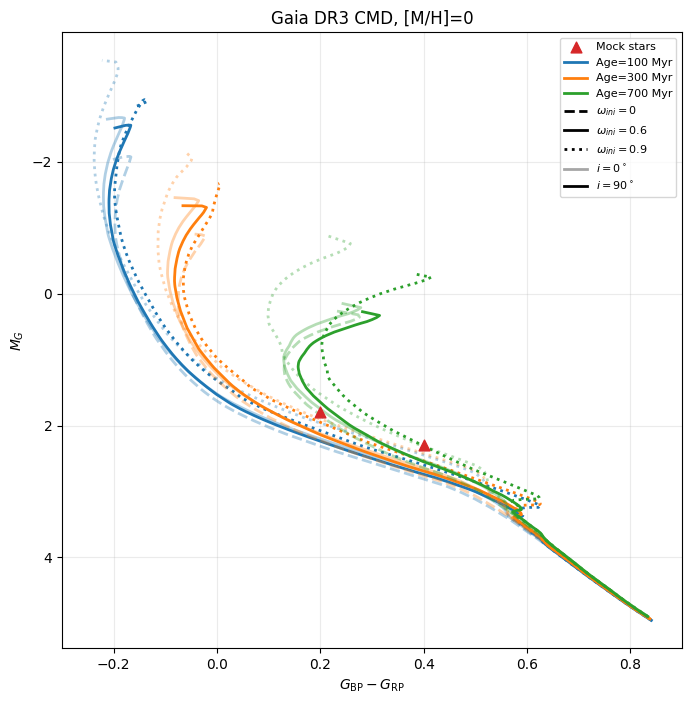

In [7]:
fig, ax = plt.subplots(figsize=(8, 8))

observed_color = [0.2, 0.4]
observed_mag = [1.8, 2.3]

ax.scatter(
    observed_color, observed_mag,
    s=60, marker="^", color="tab:red", label="Mock stars", zorder=100,
)

plot_cmd_isochrones(
    interp_func_cmd,
    grid_type="with_inc",
    Age=[100, 300, 700],
    band="Gaia DR3",
    MH=0.0,
    omega_ini=[0.0, 0.6, 0.9],
    ax=ax,
    legend=True,
    xlim=[-0.3, 0.9]
)

plt.show()

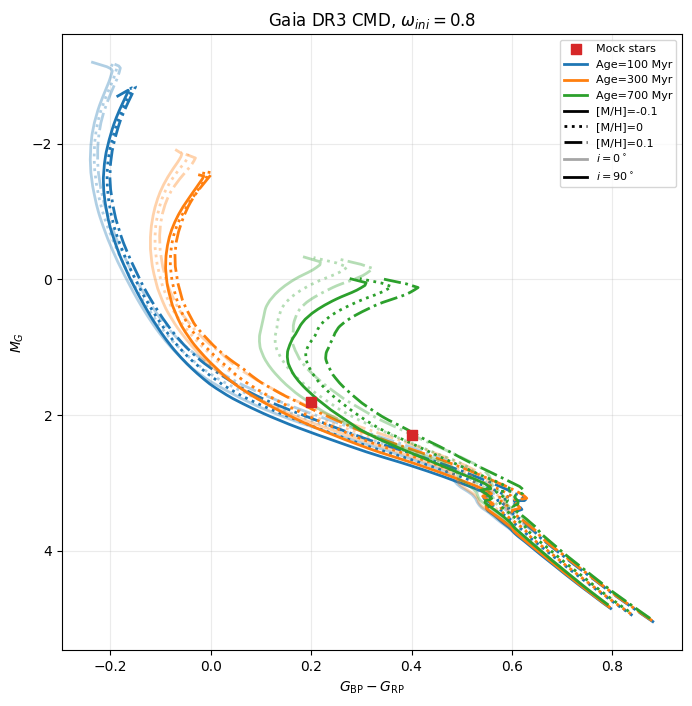

In [8]:
fig, ax = plt.subplots(figsize=(8, 8))

observed_color = [0.2, 0.4]
observed_mag = [1.8, 2.3]

ax.scatter(
    observed_color, observed_mag,
    s=60, marker="s", color="tab:red", label="Mock stars", zorder=100,
)

plot_cmd_isochrones(
    interp_func_cmd,
    grid_type="with_inc",
    Age=[100, 300, 700],
    band="Gaia DR3",
    MH=[-0.1, 0.0, 0.1],
    omega_ini=0.8,
    ax=ax,
    legend=True,
)

plt.show()